# Does wind direction matter for predicting a target turbine from a reference?

MCP (measure-correlate-predict): predict the target turbine's wind speed from a reference turbine with a straight line
`target = β · reference + α`. This notebook checks whether **one global line** is enough, or whether the relationship
changes with the wind direction, so that **one line per 30° direction sector** would predict better.

1. Figure 1: target vs reference wind speed, each point coloured by the reference wind direction.
2. Table: one line per sector, with the error of the global line vs the sector's own line.
3. Figure 2: the 12 sectors side by side.

Only training rows are used (`test_set == False`). Run as a script with other turbines:
`jupyter nbconvert --to script plot_direction_scatter.ipynb` and then `python plot_direction_scatter.py H1 T1`.

In [1]:
import sys

REF = "H1"          # reference turbine (outside the target park: H1-H5, O1, O2)
TGT = "T1"          # target turbine whose wind speed we want to predict (T1-T3)
MIN_POINTS = 150    # a sector needs at least this many points to get its own fit line

# command line: python plot_direction_scatter.py H1 T1
# (inside Jupyter sys.argv holds the kernel's own options like "-f ...", which are ignored here)
if len(sys.argv) == 3 and not sys.argv[1].startswith("-"):
    REF, TGT = sys.argv[1], sys.argv[2]
print(f"reference = {REF}, target = {TGT}")

reference = H1, target = T1


## Load the training data

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA_DIR = Path("data")
OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)


def load_turbine(name):
    """Training rows (test_set == False) of one turbine: timestamp, wind speed, wind direction.

    get_dataset.load_turbines drops the test_set column, so the file is read directly here.
    """
    df = pd.read_excel(DATA_DIR / f"{name}_data.xlsx")
    df = df[~df["test_set"].astype(bool)].copy()
    # Excel stores times as float days; round away the float noise (e.g. 00:09:59.999)
    df["timestamp"] = pd.to_datetime(df["timestamp"]).dt.round("s")
    return df[["timestamp", "wind_speed", "wind_direction"]]


# one row per timestamp with both turbines side by side; drop rows where any value is missing
df = load_turbine(REF).merge(load_turbine(TGT), on="timestamp", suffixes=("_ref", "_tgt")).dropna()
x, y = df["wind_speed_ref"], df["wind_speed_tgt"]
print(f"{len(df)} training rows, {df['timestamp'].min()} -> {df['timestamp'].max()}")

11229 training rows, 2026-07-01 00:00:00 -> 2026-09-30 23:50:00


## Global fit: one straight line for all directions

In [3]:
def fit_line(x, y):
    """Ordinary least squares line y = beta * x + alpha, plus the Pearson correlation r."""
    beta, alpha = np.polyfit(x, y, 1)
    r = np.corrcoef(x, y)[0, 1]
    return beta, alpha, r


def rmse(predicted, actual):
    """Root mean squared error in m/s."""
    return float(np.sqrt(np.mean((predicted - actual) ** 2)))


def wrap180(deg):
    """Wrap angles in degrees to [-180, 180)."""
    return (deg + 180) % 360 - 180


def circular_mean(deg):
    """Mean of angles in degrees via the mean unit vector (so the mean of 350° and 10° is 0°, not 180°)."""
    rad = np.radians(deg)
    return float(wrap180(np.degrees(np.arctan2(np.sin(rad).mean(), np.cos(rad).mean()))))


beta_g, alpha_g, r_g = fit_line(x, y)
df["pred_global"] = alpha_g + beta_g * x
print(f"global fit: {TGT} = {beta_g:.3f} * {REF} + {alpha_g:.3f}   (r = {r_g:.3f}, n = {len(df)})")

global fit: T1 = 0.697 * H1 + 1.325   (r = 0.695, n = 11229)


## Figure 1: target vs reference, coloured by reference wind direction

If direction did not matter, the colours would be mixed evenly around the black line. Colours that sit above or
below the line mean that the target is faster or slower than the global line predicts when the wind blows from
those directions.

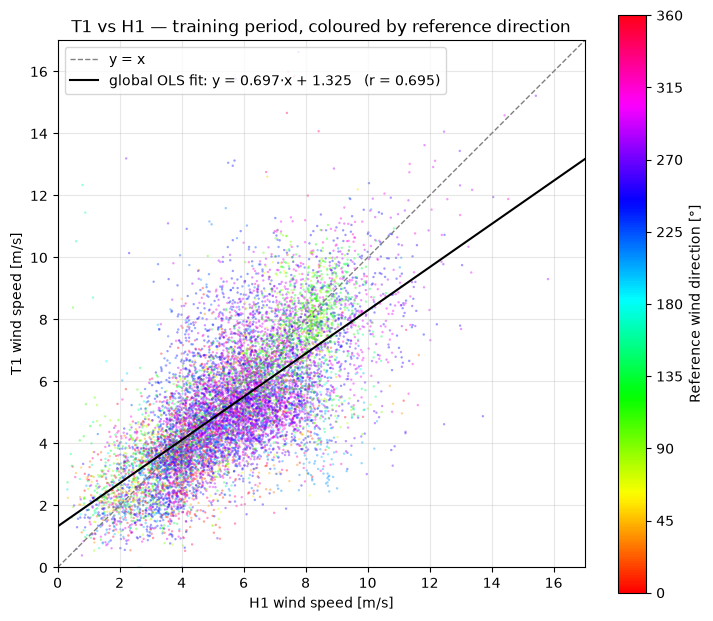

In [4]:
lim = np.array([0, np.ceil(max(x.max(), y.max()))])

fig, ax = plt.subplots(figsize=(8.5, 7.5))
points = ax.scatter(x, y, c=df["wind_direction_ref"], cmap="hsv", vmin=0, vmax=360, s=3, alpha=0.4, linewidths=0)
ax.plot(lim, lim, "--", color="grey", linewidth=1, label="y = x")
ax.plot(lim, alpha_g + beta_g * lim, color="black", linewidth=1.5,
        label=f"global OLS fit: y = {beta_g:.3f}·x + {alpha_g:.3f}   (r = {r_g:.3f})")

colorbar = fig.colorbar(points, ax=ax, label="Reference wind direction [°]", ticks=range(0, 361, 45))
colorbar.solids.set_alpha(1)   # full colours in the colorbar even though the points are transparent

ax.set(xlim=lim, ylim=lim, aspect="equal", xlabel=f"{REF} wind speed [m/s]", ylabel=f"{TGT} wind speed [m/s]",
       title=f"{TGT} vs {REF} — training period, coloured by reference direction")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
fig.savefig(OUT_DIR / f"direction_scatter_{REF}_{TGT}.png", dpi=150, bbox_inches="tight")
plt.show()

## Per-sector statistics

Each row goes into one of 12 sectors of 30° by the **reference** direction, centred on north: sector 0 = 345–15°,
sector 1 = 15–45°, ... Every sector with at least 150 points gets its own line. Sectors with fewer points keep the
global line. `mean_veer` is the average direction difference target − reference (circular mean, in degrees).

In [5]:
df["sector"] = ((df["wind_direction_ref"] + 15) % 360 // 30).astype(int)


def sector_range(sector):
    """Direction range of a sector, e.g. 0 -> '345–15°'."""
    return f"{(sector * 30 - 15) % 360}–{(sector * 30 + 15) % 360}°"


df["pred_sector"] = df["pred_global"]   # fallback: the global line, replaced below where a sector has enough points
rows = []
for sector in range(12):
    part = df[df["sector"] == sector]
    n = len(part)
    beta = alpha = r = np.nan
    if n >= MIN_POINTS:
        beta, alpha, r = fit_line(part["wind_speed_ref"], part["wind_speed_tgt"])
        df.loc[part.index, "pred_sector"] = alpha + beta * part["wind_speed_ref"]
    part = df.loc[part.index]   # now with the sector predictions
    rows.append({
        "sector": sector,
        "range": sector_range(sector),
        "n": n,
        "beta": beta,
        "alpha": alpha,
        "r": r,
        "rmse_global_fit": rmse(part["pred_global"], part["wind_speed_tgt"]) if n else np.nan,
        "rmse_sector_fit": rmse(part["pred_sector"], part["wind_speed_tgt"]) if n else np.nan,
        "mean_veer": circular_mean(part["wind_direction_tgt"] - part["wind_direction_ref"]) if n else np.nan,
    })
stats = pd.DataFrame(rows)

stats_path = OUT_DIR / f"sector_stats_{REF}_{TGT}.csv"
stats.to_csv(stats_path, index=False)
print(stats.round(3).to_string(index=False))
print(f"\nsaved to {stats_path}")

rmse_global = rmse(df["pred_global"], df["wind_speed_tgt"])
rmse_sector = rmse(df["pred_sector"], df["wind_speed_tgt"])
print(f"\ntraining RMSE, one global line:   {rmse_global:.3f} m/s")
print(f"training RMSE, one line per sector: {rmse_sector:.3f} m/s  ({100 * (1 - rmse_sector / rmse_global):.1f}% lower)")
# both are errors on the data the lines were fitted on: 12 lines can only fit at least as well as 1 line here,
# so check the gain on held-out data before relying on it

 sector    range    n  beta  alpha     r  rmse_global_fit  rmse_sector_fit  mean_veer
      0  345–15°  568 0.617  1.443 0.598            1.435            1.405     -5.412
      1   15–45°  302 0.394  1.945 0.558            1.403            1.074      8.864
      2   45–75°  408 0.774  0.914 0.732            1.410            1.402     11.094
      3  75–105°  657 0.799  1.052 0.800            1.442            1.377      2.570
      4 105–135°  843 0.812  1.089 0.850            1.265            1.158     -3.366
      5 135–165°  533 0.668  1.612 0.762            1.435            1.428     -3.489
      6 165–195°  263 0.533  1.735 0.702            1.295            1.183     -1.002
      7 195–225°  748 0.419  2.270 0.458            1.886            1.709      1.699
      8 225–255° 1919 0.736  1.456 0.677            1.747            1.708     -2.070
      9 255–285° 1953 0.572  1.618 0.616            1.433            1.346      5.742
     10 285–315° 2243 0.725  1.344 0.722            1.

## Figure 2: one panel per direction sector

Grey dashed = global line (same in every panel), red = the sector's own line. The more the red lines differ
from the grey one, the more the wind direction matters.

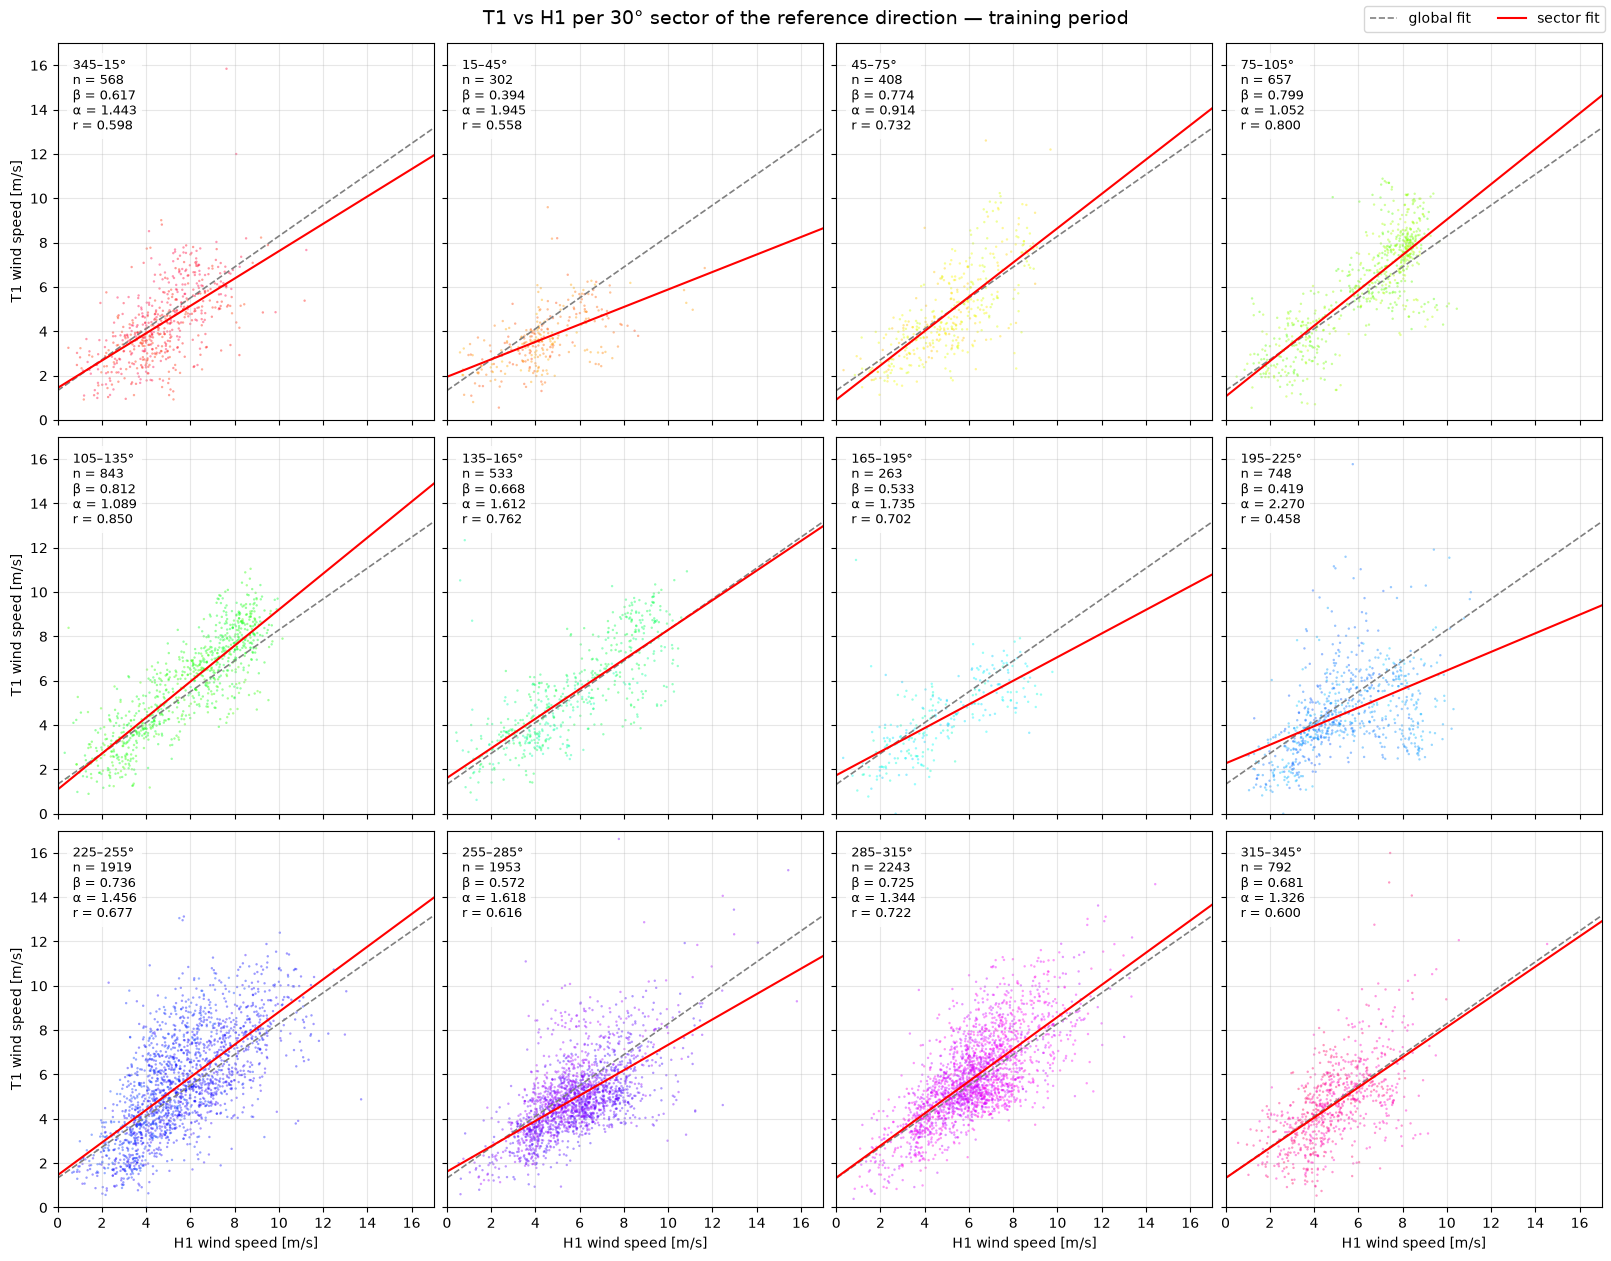

In [6]:
fig, axes = plt.subplots(3, 4, figsize=(16, 12.5), sharex=True, sharey=True, layout="constrained")
for sector, ax in zip(range(12), axes.flat):
    part = df[df["sector"] == sector]
    s = stats.loc[sector]
    ax.scatter(part["wind_speed_ref"], part["wind_speed_tgt"], c=part["wind_direction_ref"], cmap="hsv",
               vmin=0, vmax=360, s=3, alpha=0.4, linewidths=0)
    ax.plot(lim, alpha_g + beta_g * lim, "--", color="grey", linewidth=1.2, label="global fit")
    if s["n"] >= MIN_POINTS:
        ax.plot(lim, s["alpha"] + s["beta"] * lim, color="red", linewidth=1.5, label="sector fit")
        text = f"{s['range']}\nn = {s['n']}\nβ = {s['beta']:.3f}\nα = {s['alpha']:.3f}\nr = {s['r']:.3f}"
    else:
        text = f"{s['range']}\nn = {s['n']}\ntoo few points"
    ax.text(0.04, 0.96, text, transform=ax.transAxes, va="top", fontsize=9,
            bbox=dict(facecolor="white", alpha=0.85, edgecolor="none"))
    ax.set(xlim=lim, ylim=lim)
    ax.grid(alpha=0.3)
for ax in axes[-1]:
    ax.set_xlabel(f"{REF} wind speed [m/s]")
for ax in axes[:, 0]:
    ax.set_ylabel(f"{TGT} wind speed [m/s]")
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper right", ncols=2)
fig.suptitle(f"{TGT} vs {REF} per 30° sector of the reference direction — training period", fontsize=14)
fig.savefig(OUT_DIR / f"direction_sectors_{REF}_{TGT}.png", dpi=150, bbox_inches="tight")
plt.show()